In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import warnings
warnings.filterwarnings('ignore')

In [2]:
# ML Tools
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

# Jupyter display tools
from IPython.display import display, Markdown, clear_output

In [3]:
# 1. Загрузка данных
try:
    df = pd.read_csv('random_short_file.csv')
except FileNotFoundError:
    print("Файл не найден, пожалуйста, загрузите датасет в ту же папку.")

In [4]:
# Очистка и подготовка
cols_to_use = ['Severity', 'Temperature(F)', 'Wind_Speed(mph)']
df_clean = df[cols_to_use].dropna()

# Убираем аномальные выбросы
df_clean = df_clean[(df_clean['Wind_Speed(mph)'] <= 100) & (df_clean['Wind_Speed(mph)'] >= 0)]
df_clean = df_clean[(df_clean['Temperature(F)'] <= 110) & (df_clean['Temperature(F)'] >= -20)]

In [5]:
# Балансировка классов
X = df_clean[['Temperature(F)', 'Wind_Speed(mph)']].values
y = df_clean['Severity'].values

# Severity 2 доминирует. Применим SMOTE.
smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X, y)

# Делим на Train/Test (для визуализации используем Train, чтобы видеть "выученные" паттерны)
X_train, X_test, y_train, y_test = train_test_split(X_res, y_res, test_size=0.3, random_state=42)

# Масштабирование (Важно для SVM, KNN и LogReg)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

In [6]:
# Настройки визуализации
cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])
cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#0000FF', '#FFFF00'])
class_names = ['Severity 1', 'Severity 2', 'Severity 3', 'Severity 4']

In [7]:
def plot_decision_boundary(clf, title, X_train, y_train, scaler_obj, step=0.2):
    """Функция отрисовки границ решений"""
    # Снимаем масштабирование для создания физической сетки координат
    X_unscaled = scaler_obj.inverse_transform(X_train)

    x_min, x_max = X_unscaled[:, 0].min() - 5, X_unscaled[:, 0].max() + 5
    y_min, y_max = X_unscaled[:, 1].min() - 1, X_unscaled[:, 1].max() + 1

    # Создаем сетку
    xx, yy = np.meshgrid(np.arange(x_min, x_max, step),
                         np.arange(y_min, y_max, step))

    # Масштабируем сетку для предсказания
    grid_points = np.c_[xx.ravel(), yy.ravel()]
    grid_points_scaled = scaler_obj.transform(grid_points)

    # Предсказание
    try:
        Z = clf.predict(grid_points_scaled)
    except Exception as e:
        print(f"Ошибка предсказания: {e}")
        return

    Z = Z.reshape(xx.shape)

    # Отрисовка
    plt.figure(figsize=(10, 7))
    plt.contourf(xx, yy, Z, cmap=cmap_light, alpha=0.8)

    # Точки (используем несбалансированные данные для честной оценки плотности)
    X_orig = scaler_obj.inverse_transform(X_train)
    scatter = plt.scatter(X_orig[:, 0], X_orig[:, 1], c=y_train, cmap=cmap_bold,
                          edgecolor='k', s=20, alpha=0.5)

    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())
    plt.title(title, fontsize=15, fontweight='bold')
    plt.xlabel('Temperature (F)', fontsize=12)
    plt.ylabel('Wind_Speed (mph)', fontsize=12)

    # Легенда
    handles, _ = scatter.legend_elements()
    plt.legend(handles, class_names, loc="best")
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()

## 1. Логистическая регрессия (Multinomial)
**Гипотеза:** Проверка линейной разделимости классов в пространстве Температура-Скорость ветра.

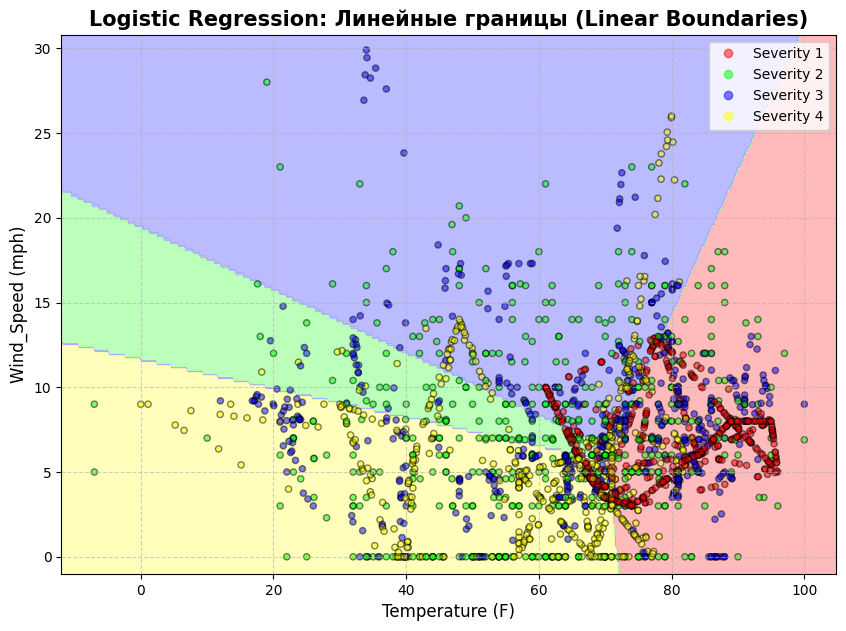

In [8]:
# 1. Логистическая Регрессия (Multinomial)
lr = LogisticRegression(multi_class='multinomial', solver='newton-cg', max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train)
plot_decision_boundary(lr, "Logistic Regression: Линейные границы (Linear Boundaries)", X_train_scaled, y_train, scaler)


## 2. Дерево решений (max_depth=4)
**Гипотеза:** Выявление жестких ортогональных (ступенчатых) правил ПДД и физики.

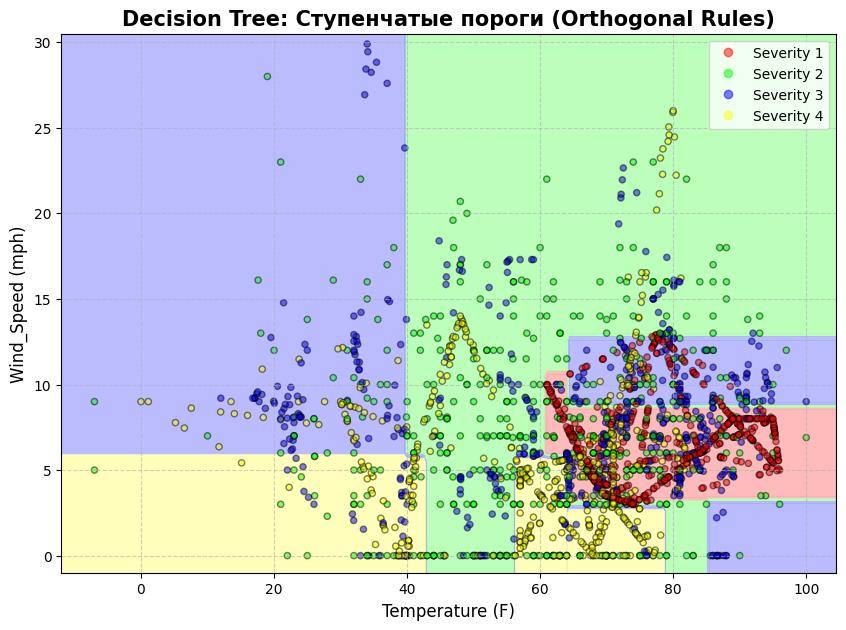

In [9]:
# 2. Дерево решений (Decision Tree)
tree = DecisionTreeClassifier(max_depth=4, random_state=42)
tree.fit(X_train_scaled, y_train)
plot_decision_boundary(tree, "Decision Tree: Ступенчатые пороги (Orthogonal Rules)", X_train_scaled, y_train, scaler, step=0.5)

## 3. KNN (k=30)
**Гипотеза:** Поиск локальных аномалий и кластеров, не описываемых глобальными правилами.

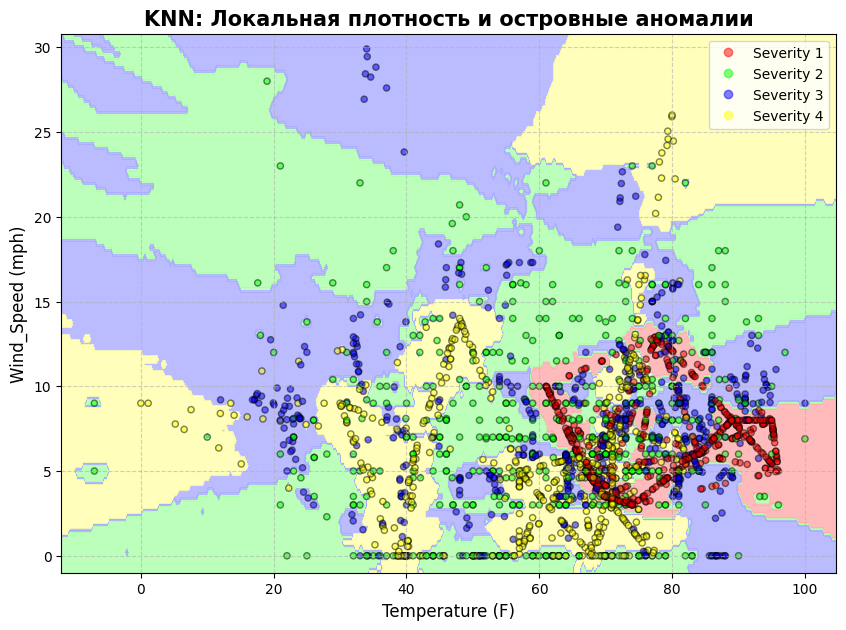

In [10]:
# 3. KNN (Метод k-ближайших соседей)
knn = KNeighborsClassifier(n_neighbors=30, weights='distance')
knn.fit(X_train_scaled, y_train)
plot_decision_boundary(knn, "KNN: Локальная плотность и островные аномалии", X_train_scaled, y_train, scaler, step=0.3)

## 4. SVM (RBF Kernel)
**Гипотеза:** Поиск сложных нелинейных «островных» границ.

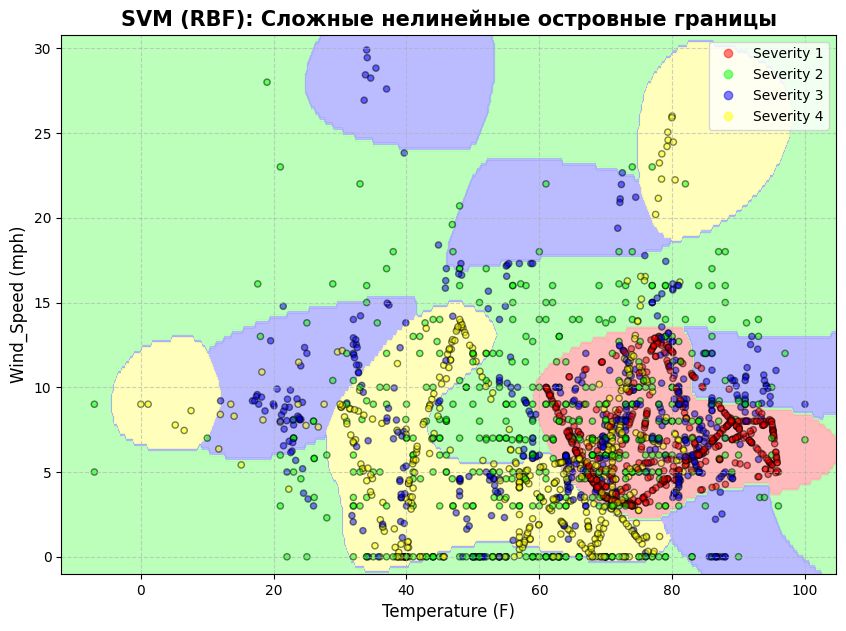

In [11]:
# 4. SVM (Support Vector Machine, RBF)
# Сэмплирование для SVM
sample_idx = np.random.choice(X_train_scaled.shape[0], 2000, replace=False)
svm = SVC(kernel='rbf', C=10, gamma='scale', random_state=42)
svm.fit(X_train_scaled[sample_idx], y_train[sample_idx])
plot_decision_boundary(svm, "SVM (RBF): Сложные нелинейные островные границы", X_train_scaled[sample_idx], y_train[sample_idx], scaler, step=0.3)

## 5. XGBoost (Ансамбль деревьев)
**Гипотеза:** Как ансамбли «сглаживают» шум и переобучение одиночного дерева.

In [12]:
# 5. XGBoost (Ансамбль)
# XGBoost требует меток от 0 до N-1
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
xgb = XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.1, random_state=42, use_label_encoder=False, eval_metric='mlogloss')
xgb.fit(X_train_scaled, y_train_enc)

,objective,'multi:softprob'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'mlogloss'


In [13]:
# Адаптация функции predict для LabelEncoder
class XGBWrapper:
    def __init__(self, model, encoder):
        self.model = model
        self.encoder = encoder
    def predict(self, X):
        preds = self.model.predict(X)
        return self.encoder.inverse_transform(preds)

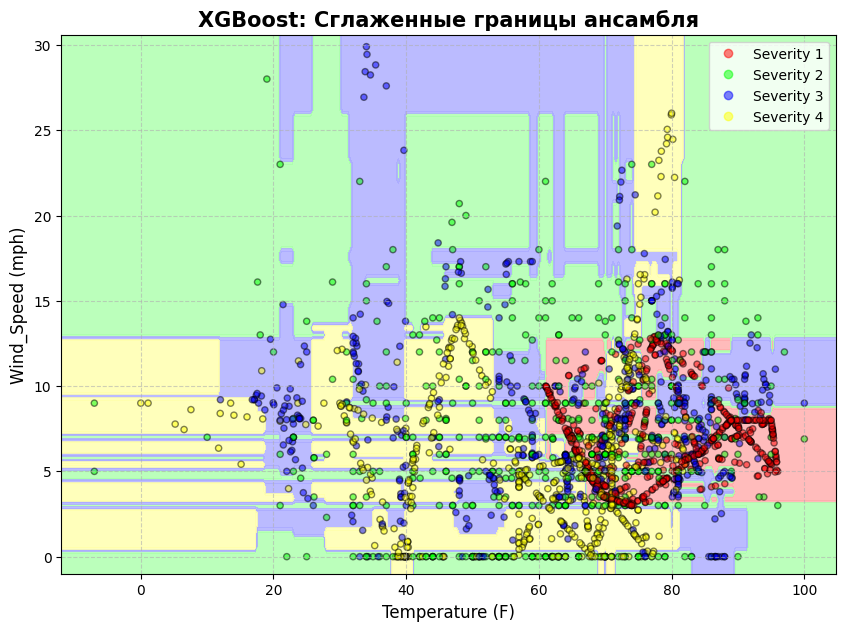

In [14]:
xgb_wrapper = XGBWrapper(xgb, le)
plot_decision_boundary(xgb_wrapper, "XGBoost: Сглаженные границы ансамбля", X_train_scaled, y_train, scaler, step=0.4)